In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer(as_frame=True)
X= data.data
y=data.target

correlation_matrix = X.corr()
print(correlation_matrix)

                         mean radius  mean texture  mean perimeter  mean area  \
mean radius                 1.000000      0.323782        0.997855   0.987357   
mean texture                0.323782      1.000000        0.329533   0.321086   
mean perimeter              0.997855      0.329533        1.000000   0.986507   
mean area                   0.987357      0.321086        0.986507   1.000000   
mean smoothness             0.170581     -0.023389        0.207278   0.177028   
mean compactness            0.506124      0.236702        0.556936   0.498502   
mean concavity              0.676764      0.302418        0.716136   0.685983   
mean concave points         0.822529      0.293464        0.850977   0.823269   
mean symmetry               0.147741      0.071401        0.183027   0.151293   
mean fractal dimension     -0.311631     -0.076437       -0.261477  -0.283110   
radius error                0.679090      0.275869        0.691765   0.732562   
texture error              -

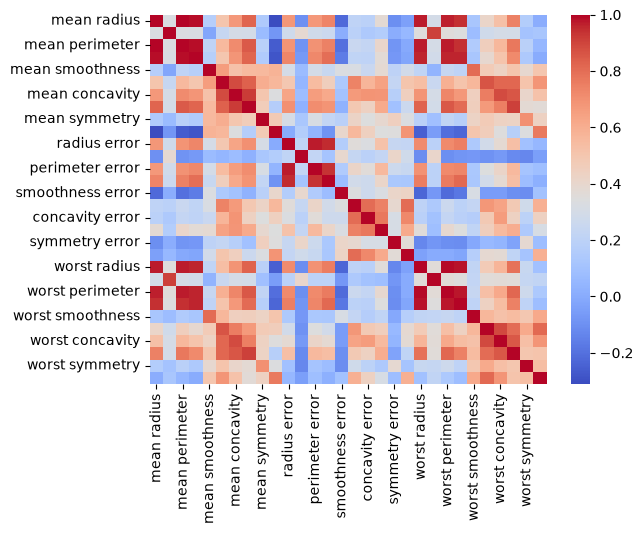

In [5]:
sns.heatmap(correlation_matrix, cmap='coolwarm')
plt.show()

In [6]:
# mean radiuc, mean perimeter, mean concavity, worst perimeter, worst raidus:

# do not automaticcally delete highly correlated features.

In [10]:
#lets first inverstigate it:
print(correlation_matrix['mean radius'].sort_values(ascending= False).head(5))

mean radius        1.000000
mean perimeter     0.997855
mean area          0.987357
worst radius       0.969539
worst perimeter    0.965137
Name: mean radius, dtype: float64


In [11]:
# here we can remove , mean perimeter, mean area, worst perimeter and other features

# SELECT KBEST

In [19]:
# Analysis of Variance (ANOVA  F -test): method used to compare the means of 2 or more group
# here we do assumptions: 1. normally distributed dataset 3. absence of outliers
# F-statistic higher -> mean differs between classes

from sklearn.feature_selection import SelectKBest, f_classif

X_train, X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)

pipeline = Pipeline([
    ("selection", SelectKBest(score_func=f_classif, k =10)),
    ("scaler",StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

pipeline.fit(X_train,y_train)
y_pred = pipeline.predict(X_test)

selector = pipeline.named_steps['selection']
selected_features = X.columns[selector.get_support()]
print(selected_features.tolist())


['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


In [21]:
# inspect feature scores:
scores = pd.DataFrame({
    "feature": X.columns,
    "F_score": selector.scores_,
    "p_value": selector.pvalues_,
    "selected": selector.get_support()
})

print(scores.sort_values("F_score", ascending=False))

                    feature     F_score        p_value  selected
27     worst concave points  795.223341  9.269318e-102      True
22          worst perimeter  719.598823   1.327313e-95      True
7       mean concave points  703.364031   3.135578e-94      True
20             worst radius  687.430367   7.296427e-93      True
2            mean perimeter  565.485755   1.011815e-81      True
23               worst area  541.713694   2.150031e-79      True
0               mean radius  523.613907   1.387363e-77      True
3                 mean area  469.516453   5.741182e-72      True
6            mean concavity  416.374874   4.058059e-66      True
26          worst concavity  365.747389   3.351548e-60      True
5          mean compactness  269.466042   7.418408e-48     False
25        worst compactness  257.926057   2.885121e-46     False
13               area error  214.858763   4.296371e-40     False
10             radius error  212.499767   9.611165e-40     False
12          perimeter err